# Predicting 90-day customer spending

Source: Chen (2012), Online Retail II, UCI, CC BY 4.0. Run the pipeline before this notebook. Figures describe historical purchases, not loyalty membership or causal offer effects.

In [1]:
from pathlib import Path
import json, pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/'configs').exists() else Path.cwd().parent
plt.style.use('seaborn-v0_8-whitegrid')


In [2]:
from loyalty_ml.train_value import train
from loyalty_ml.features import FEATURES
from loyalty_ml.evaluate import value_metrics
x=pd.read_parquet(ROOT/'data/processed/customer_snapshots.parquet')
training=x[x.snapshot_date<'2011-06-01'];validation=x[x.snapshot_date=='2011-06-01'];test=x[x.snapshot_date=='2011-09-01']
model,name,results=train(training,validation)
pd.Series(results,name='Validation MAE, GBP')

historical_spending    457.517306
tweedie_glm            436.646691
lightgbm_tweedie       404.705777
Name: Validation MAE, GBP, dtype: float64

In [3]:
pred=model.predict(test[FEATURES])
pd.DataFrame({'selected_model':value_metrics(test.future_spend_90,pred),'historical_baseline':value_metrics(test.future_spend_90,test.spend_90)})

,selected_model,historical_baseline
mae,631.417732,631.795878
rmse,3121.169647,2655.299812
aggregate_bias_pct,-48.823985,-23.501470


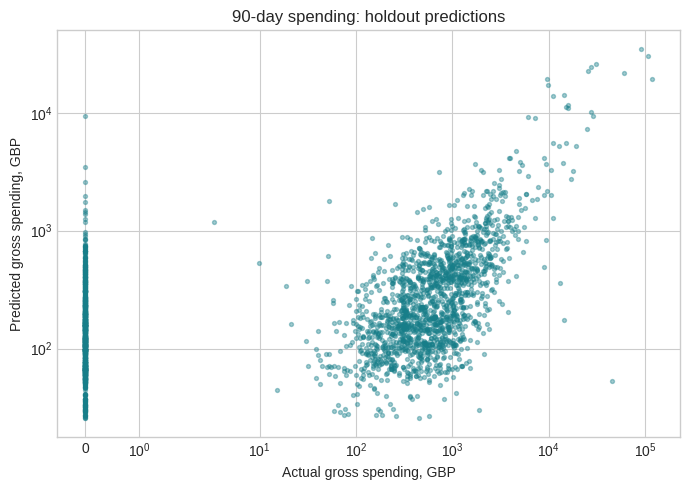

In [4]:
plt.figure(figsize=(7,5));plt.scatter(test.future_spend_90,pred,s=8,alpha=.4,color='#177e89')
plt.xscale('symlog');plt.yscale('symlog');plt.xlabel('Actual gross spending, GBP');plt.ylabel('Predicted gross spending, GBP')
plt.title('90-day spending: holdout predictions');plt.tight_layout();plt.show()

## Interpretation
Compare against the baseline and report limitations. No purchase for 90 days does not prove permanent churn. Large wholesale purchases can dominate spending error. Survival diagnostics can reject proportional hazards; the Cox model is exploratory if that assumption fails. Retention priority is a heuristic requiring an experiment before claiming campaign benefit.